# 05 — Causal Analysis

**Project:** Causal ML for Climate Policy Effectiveness  
**Purpose:** Estimate average and heterogeneous treatment effects using DML & Causal Forest  
**Input:** `data/processed/analysis_panel.csv`  
**Output:** Causal estimates, CATEs, model comparison tables

---

## Methods
1. **Baseline:** OLS with country and year fixed effects  
2. **Double/Debiased ML (DML):** Flexible first-stage models (XGBoost) with cross-fitting  
3. **Causal Forest:** Heterogeneous treatment effects via Generalized Random Forests  
4. **Multi-treatment analysis:** Separate effects for carbon pricing, renewable mandates, efficiency standards

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.causal_models import run_ols_baseline, run_dml, run_causal_forest, compare_methods
from src.visualization import set_publication_style, save_figure, COLORS

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
set_publication_style()

In [2]:
# Load analysis panel
panel = pd.read_csv(PROCESSED_DIR / "analysis_panel.csv")
print(f"Panel: {panel.shape[0]:,} rows × {panel.shape[1]} columns")
print(f"Countries: {panel['iso3'].nunique()}, Years: {panel['year'].min()}-{panel['year'].max()}")

Panel: 7,630 rows × 74 columns
Countries: 218, Years: 1990-2024


In [3]:
# Define analysis variables
OUTCOME = "log_co2"
TREATMENTS = [c for c in panel.columns if c.startswith("treat_") and panel[c].std() > 0]

# NOTE: the sample below is restricted to units with non-missing governance
# (regulatory_quality) and renewables-share data, which is a materially
# smaller/different sample than the 4-covariate Baseline spec used in the
# robustness checks (~6,655-6,845 obs, see Notebook 06 Sec 6.3). Previously
# this restriction was applied *without* actually including those two
# covariates in the regression -- i.e. the main comparison table quietly ran
# on the Extended-specification sample while only controlling for the
# Baseline covariate set. That mismatch (a governance/renewables-restricted
# sample of N=2,028 without governance/renewables controls) is what produced
# the abstract-vs-Table-3 sample-size confusion. Fixed here by explicitly
# using the Extended covariate set (6 covariates) to match the sample
# restriction, so the main method-comparison table is unambiguously "the
# Extended specification, N=2,028" -- consistent with Table 4's robustness
# ladder, where Extended is the richest-covariate spec.
potential_covariates = [
    "population", "gdp_per_capita", "urban_pct", "co2_lag1",
    "regulatory_quality", "renewables_share_energy",
]
COVARIATES = [c for c in potential_covariates if c in panel.columns]

# Ensure consistent sample for all methods
required_cols = [OUTCOME] + TREATMENTS + COVARIATES
required_cols = [c for c in required_cols if c in panel.columns]
panel = panel.dropna(subset=required_cols).copy()

print(f"Outcome: {OUTCOME}")
print(f"Treatments: {TREATMENTS}")
print(f"Covariates ({len(COVARIATES)}) [Extended specification]: {COVARIATES}")
print(f"Sample size after dropping missing values across all required columns: {len(panel)}")

Outcome: log_co2
Treatments: ['treat_carbon_pricing', 'treat_renewable_mandate', 'treat_efficiency_standard']
Covariates (6) [Extended specification]: ['population', 'gdp_per_capita', 'urban_pct', 'co2_lag1', 'regulatory_quality', 'renewables_share_energy']
Sample size after dropping missing values across all required columns: 2028


---
## 5.1 — Baseline: OLS Fixed Effects

In [4]:
print("=" * 60)
print("5.1 — Baseline OLS Estimates")
print("=" * 60)

ols_results = []
for treat in TREATMENTS:
    try:
        est = run_ols_baseline(panel, OUTCOME, treat, COVARIATES, fe_cols=["iso3", "year"])
        ols_results.append(est)
        sig = "***" if est.is_significant else ""
        print(f"  {treat:30s}: {est.estimate:+.4f} [{est.ci_lower:.4f}, {est.ci_upper:.4f}] {sig}")
    except Exception as e:
        print(f"  {treat:30s}: FAILED — {e}")

if ols_results:
    print(f"\n{compare_methods(ols_results).to_string(index=False)}")

5.1 — Baseline OLS Estimates


  treat_carbon_pricing          : +0.1046 [0.0049, 0.2042] ***
  treat_renewable_mandate       : +0.0119 [-0.0728, 0.0966] 


  treat_efficiency_standard     : +0.1196 [-0.0112, 0.2504] 

Method                 Treatment Estimate Std. Error            95% CI p-value    N Significant
   OLS      treat_carbon_pricing   0.1046     0.0508  [0.0049, 0.2042]  0.0397 2028         ***
   OLS   treat_renewable_mandate   0.0119     0.0432 [-0.0728, 0.0966]  0.7828 2028            
   OLS treat_efficiency_standard   0.1196     0.0667 [-0.0112, 0.2504]  0.0731 2028            


---
## 5.2 — Double/Debiased ML (DML)

In [5]:
print("=" * 60)
print("5.2 — Double/Debiased ML Estimates")
print("=" * 60)

dml_results = []
for treat in TREATMENTS:
    print(f"\n  Estimating DML for: {treat}")
    try:
        est = run_dml(panel, OUTCOME, treat, COVARIATES,
                      n_folds=5, first_stage_model="xgboost")
        dml_results.append(est)
        sig = "***" if est.is_significant else ""
        print(f"    ATE: {est.estimate:+.4f} [{est.ci_lower:.4f}, {est.ci_upper:.4f}] {sig}")
        print(f"    N={est.n_obs:,}, Treated={est.n_treated:,}")
    except Exception as e:
        print(f"    FAILED: {e}")

if dml_results:
    print(f"\n{compare_methods(dml_results).to_string(index=False)}")

5.2 — Double/Debiased ML Estimates

  Estimating DML for: treat_carbon_pricing


    ATE: -0.0057 [-0.0234, 0.0119] 
    N=2,028, Treated=1,419

  Estimating DML for: treat_renewable_mandate


    ATE: -0.0146 [-0.0292, -0.0000] ***
    N=2,028, Treated=1,414

  Estimating DML for: treat_efficiency_standard


    ATE: +0.0070 [-0.0183, 0.0323] 
    N=2,028, Treated=1,586

       Method                 Treatment Estimate Std. Error             95% CI p-value    N Significant
DML (xgboost)      treat_carbon_pricing  -0.0057     0.0090  [-0.0234, 0.0119]  0.5249 2028            
DML (xgboost)   treat_renewable_mandate  -0.0146     0.0075 [-0.0292, -0.0000]  0.0494 2028         ***
DML (xgboost) treat_efficiency_standard   0.0070     0.0129  [-0.0183, 0.0323]  0.5888 2028            


In [6]:
# DML with alternative first-stage (Random Forest)
print("\n--- DML with Random Forest first stage ---")

dml_rf_results = []
primary_treat = TREATMENTS[0] if TREATMENTS else None

if primary_treat:
    for model_type in ["xgboost", "random_forest", "gradient_boosting"]:
        try:
            est = run_dml(panel, OUTCOME, primary_treat, COVARIATES,
                          n_folds=5, first_stage_model=model_type)
            dml_rf_results.append(est)
            print(f"  {model_type:25s}: {est.estimate:+.4f} [{est.ci_lower:.4f}, {est.ci_upper:.4f}]")
        except Exception as e:
            print(f"  {model_type:25s}: FAILED — {e}")


--- DML with Random Forest first stage ---


  xgboost                  : -0.0057 [-0.0234, 0.0119]


  random_forest            : -0.0109 [-0.0240, 0.0022]


  gradient_boosting        : -0.0097 [-0.0256, 0.0063]


---
## 5.3 — Causal Forest: Heterogeneous Effects

In [7]:
print("=" * 60)
print("5.3 — Causal Forest (Heterogeneous Treatment Effects)")
print("=" * 60)

if primary_treat and primary_treat in panel.columns:
    # Effect modifiers — variables we think might moderate the treatment effect
    effect_modifiers = [c for c in ["gdp_per_capita", "regulatory_quality",
                                     "renewables_share_energy", "urban_pct"]
                        if c in panel.columns]
    
    if not effect_modifiers:
        effect_modifiers = COVARIATES[:4]  # fallback
    
    print(f"  Treatment: {primary_treat}")
    print(f"  Effect modifiers: {effect_modifiers}")
    
    try:
        cf_ate, cate_df = run_causal_forest(
            panel, OUTCOME, primary_treat, COVARIATES,
            effect_modifier_cols=effect_modifiers,
            n_estimators=500,
        )
        print(f"\n  ATE from Causal Forest: {cf_ate.estimate:+.4f} [{cf_ate.ci_lower:.4f}, {cf_ate.ci_upper:.4f}]")
        print(f"  CATE range: [{cate_df['cate'].min():.4f}, {cate_df['cate'].max():.4f}]")
        print(f"  CATE std: {cate_df['cate'].std():.4f}")
        
        # Save CATEs
        cate_df.to_csv(PROCESSED_DIR / "cate_estimates.csv", index=False)
        print(f"   CATEs saved to {PROCESSED_DIR / 'cate_estimates.csv'}")
    except Exception as e:
        print(f"   Causal Forest failed: {e}")
        cf_ate = None
        cate_df = None

5.3 — Causal Forest (Heterogeneous Treatment Effects)
  Treatment: treat_carbon_pricing
  Effect modifiers: ['gdp_per_capita', 'regulatory_quality', 'renewables_share_energy', 'urban_pct']



  ATE from Causal Forest: -0.0081 [-0.0776, 0.0613]
  CATE range: [-0.1064, 0.0933]
  CATE std: 0.0271
   CATEs saved to F:\Nexus_Projects\causal-climate-policy\data\processed\cate_estimates.csv


---
## 5.4 — Method Comparison

In [8]:
print("=" * 60)
print("5.4 — Method Comparison")
print("=" * 60)

all_estimates = []
if ols_results:
    all_estimates.extend(ols_results)
if dml_results:
    all_estimates.extend(dml_results)
if cf_ate:
    all_estimates.append(cf_ate)

if all_estimates:
    comparison = compare_methods(all_estimates)
    print(comparison.to_string(index=False))
    
    # Save
    comparison.to_csv(PROJECT_ROOT / "outputs" / "tables" / "method_comparison.csv", index=False)
    print(f"\n Comparison table saved")
    print("  Proceed to Notebook 06: Robustness Checks")

5.4 — Method Comparison
       Method                 Treatment Estimate Std. Error             95% CI p-value    N Significant
          OLS      treat_carbon_pricing   0.1046     0.0508   [0.0049, 0.2042]  0.0397 2028         ***
          OLS   treat_renewable_mandate   0.0119     0.0432  [-0.0728, 0.0966]  0.7828 2028            
          OLS treat_efficiency_standard   0.1196     0.0667  [-0.0112, 0.2504]  0.0731 2028            
DML (xgboost)      treat_carbon_pricing  -0.0057     0.0090  [-0.0234, 0.0119]  0.5249 2028            
DML (xgboost)   treat_renewable_mandate  -0.0146     0.0075 [-0.0292, -0.0000]  0.0494 2028         ***
DML (xgboost) treat_efficiency_standard   0.0070     0.0129  [-0.0183, 0.0323]  0.5888 2028            
Causal Forest      treat_carbon_pricing  -0.0081     0.0354  [-0.0776, 0.0613]  0.8185 2028            

 Comparison table saved
  Proceed to Notebook 06: Robustness Checks


---
## 5.5 — Sector-Level Analysis

Uses `log_co2_<sector>` outcomes (Power, Transport, Industry, Agriculture),
merged from `wdi_sector_emissions.csv` in Notebook 02, with `run_models_by_sector`
-- the same `run_ols_baseline`/`run_dml` functions used for the national ATE
above, applied per sector. This replaces a prior `sector_estimates.csv` that
had no traceable generating code anywhere in the repository and was
sign-inconsistent with the national results.

Policy treatment in the underlying Climate Policy Database is national, not
sector-specific, so the same national treatment indicator is used across all
sector regressions for a given country-year; sector heterogeneity is
captured through the sector-specific outcome, not a sector-specific treatment.
This is a limitation worth stating explicitly in the manuscript.

5.5 — Sector-Level Estimates


     Sector        Method            Treatment Estimate Std. Error            95% CI p-value    N Significant
      power           OLS treat_carbon_pricing   0.0820     0.0776 [-0.0701, 0.2341]  0.2908 1950            
      power DML (xgboost) treat_carbon_pricing   0.0195     0.0212 [-0.0220, 0.0611]  0.3568 1950            
  transport           OLS treat_carbon_pricing   0.0569     0.0533 [-0.0476, 0.1613]  0.2857 1950            
  transport DML (xgboost) treat_carbon_pricing   0.0237     0.0205 [-0.0166, 0.0640]  0.2489 1950            
   industry           OLS treat_carbon_pricing   0.0398     0.0874 [-0.1316, 0.2112]  0.6487 1950            
   industry DML (xgboost) treat_carbon_pricing  -0.0481     0.0261 [-0.0992, 0.0031]  0.0654 1950            
agriculture           OLS treat_carbon_pricing   0.2681     0.2105 [-0.1445, 0.6806]  0.2028 1825            
agriculture DML (xgboost) treat_carbon_pricing  -0.0714     0.0710 [-0.2106, 0.0678]  0.3148 1825            

 Sector e

  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\sector_forest_plot.png


  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\sector_forest_plot.pdf


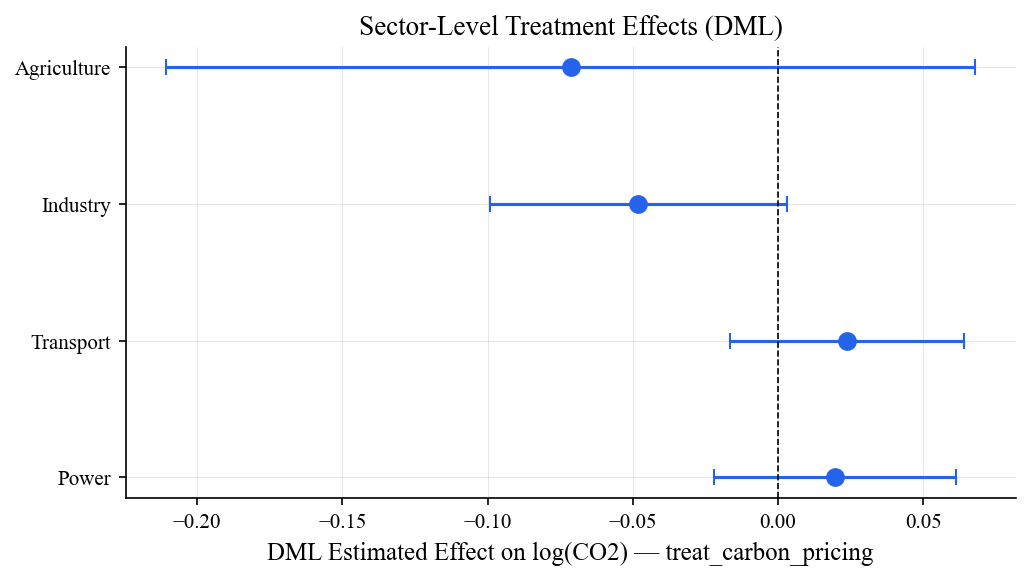

In [9]:
print("=" * 60)
print("5.5 — Sector-Level Estimates")
print("=" * 60)

from src.causal_models import run_models_by_sector

sector_results = run_models_by_sector(
    panel, primary_treat, COVARIATES,
    sectors=["power", "transport", "industry", "agriculture"],
    methods=["ols", "dml"],
    fe_cols=["iso3", "year"],
)

if len(sector_results) > 0:
    print(sector_results[["Sector", "Method", "Treatment", "Estimate", "Std. Error", "95% CI", "p-value", "N", "Significant"]].to_string(index=False))
    sector_results.to_csv(PROJECT_ROOT / "outputs" / "tables" / "sector_estimates.csv", index=False)
    print("\n Sector estimates saved to outputs/tables/sector_estimates.csv")

    # Forest plot: DML sector estimates with 95% CI
    dml_sector = sector_results[sector_results["Method"] == "DML (xgboost)"].copy()
    if len(dml_sector) > 0:
        dml_sector["est_f"] = dml_sector["Estimate"].astype(float)
        dml_sector["ci_lo"] = dml_sector["95% CI"].str.extract(r"\[(-?\d+\.\d+),")[0].astype(float)
        dml_sector["ci_hi"] = dml_sector["95% CI"].str.extract(r", (-?\d+\.\d+)\]")[0].astype(float)

        fig, ax = plt.subplots(figsize=(7, 4))
        y_pos = range(len(dml_sector))
        ax.errorbar(
            dml_sector["est_f"], y_pos,
            xerr=[dml_sector["est_f"] - dml_sector["ci_lo"], dml_sector["ci_hi"] - dml_sector["est_f"]],
            fmt="o", capsize=4, color=COLORS["primary"], markersize=8,
        )
        ax.set_yticks(list(y_pos))
        ax.set_yticklabels(dml_sector["Sector"].str.title())
        ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
        ax.set_xlabel(f"DML Estimated Effect on log(CO2) — {primary_treat}")
        ax.set_title("Sector-Level Treatment Effects (DML)")
        plt.tight_layout()
        save_figure(fig, "sector_forest_plot")
        plt.show()
else:
    print("No sector outcome columns found in panel.")